# 30 · Stateprep accuracy

**Question.** Does the prepared state reach the target infidelity ε, within its a priori bound, in both forms?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p5_stateprep",)
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p5_stateprep: 338 records, 338 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.results import primary_preparations

forms = {
    form: primary_preparations(results.rows("p5_stateprep", regime=form))
    for form in ("standard", "descriptor")
}
(epsilon,) = {row["epsilon"] for rows in forms.values() for row in rows}


def verdict(form, rows):
    """Return one line: how many records reach ε and their bound, trusted and not."""
    trusted = [r for r in rows if r["trusted"]]
    bounded = [r for r in trusted if isinstance(r["infidelity_bound"], float)]
    within = sum(r["infidelity"] <= r["infidelity_bound"] for r in bounded)
    reach = sum(r["infidelity"] <= epsilon for r in trusted)
    loose = [r for r in rows if not r["trusted"]]
    loose_reach = sum(r["infidelity"] <= epsilon for r in loose)
    return (
        f"- The {form} form: {reach} of {len(trusted)} trusted records reach ε, and {within} of "
        f"{len(bounded)} are within their a priori bound; {loose_reach} of the {len(loose)} "
        "untrusted records reach ε."
    )


lines = [f"At ε = {epsilon:g}, over each panel's primary preparation:"]
display(Markdown("\n".join(lines + [verdict(form, rows) for form, rows in forms.items()])))

At ε = 1e-06, over each panel's primary preparation:
- The standard form: 19 of 19 trusted records reach ε, and 19 of 19 are within their a priori bound; 20 of the 21 untrusted records reach ε.
- The descriptor form: 69 of 69 trusted records reach ε, and 69 of 69 are within their a priori bound; 18 of the 19 untrusted records reach ε.

Each primary preparation's infidelity against its a priori bound, from the spectrum's edge, γ, the
imaginary time and the certified tail. On the diagonal the bound is attained; the dashed line is ε.

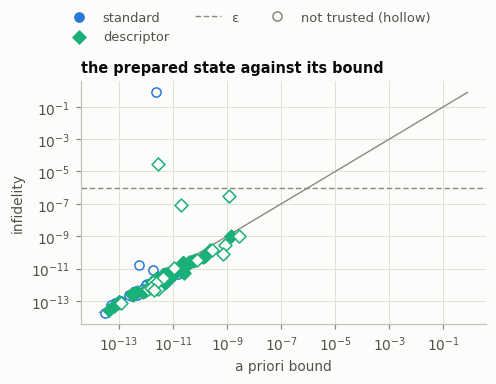

In [3]:
plotting.checks(
    [
        plotting.Check(
            forms,
            "infidelity_bound",
            "infidelity",
            "a priori bound",
            "infidelity",
            "the prepared state against its bound",
            bar=epsilon,
            bar_label="ε",
        )
    ]
);

**What this does not show.** These are exact emulations (T2), under the minimax filter in both
forms; the circuit's agreement with them is notebook 31's, and the reproduction's QITE preparations
are in the `p4_stateprep` records. The doubled space (R6) projects rather than prepares, and is notebook
12's.